# 5. Spatial Validation

## 5.1 Loading and Preparing the Dataset

In this notebook, we will evaluate the geographical generalization capability of the baseline Random Forest model.

Unlike chronological validation, spatial validation separates geographical locations between training and testing sets to evaluate the model on previously unseen locations.

### 5.1.1 Loading the Processed Dataset

Load the spatially processed weather dataset and prepare it for spatial validation.

In [1]:
# Standard Libraries
import sys
from pathlib import Path

# Add Project Root to Python Path
sys.path.insert(0, str(Path.cwd().parent))

# Project Configuration
from config import (
    PROJECT_ROOT,
    PROCESSED_DATA_PATH,
    RANDOM_STATE,
    TEST_SIZE,
    RESULTS_DIR,
    MODELS_DIR
)

# Data Libraries
import pandas as pd
import numpy as np

# Machine Learning
from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import time
import matplotlib.pyplot as plt
import json
import joblib


# Load Processed Dataset
df = pd.read_csv(PROCESSED_DATA_PATH)


print("Original dataset shape:", df.shape)

# Remove the Previously Identified Anomalous Observation
df = df[df["temperature_celsius"] <= 50].copy()

print("Dataset shape after cleaning:", df.shape)

Original dataset shape: (170928, 44)
Dataset shape after cleaning: (170927, 44)


### 5.1.2 Defining Geographical Groups

Each geographical location will be treated as a separate group using its country and location name.

This grouping ensures that observations belonging to the same geographical location are assigned to either the training set or the testing set, rather than being distributed across both.

In [2]:
# Create Geographical Group Identifier
df["location_group"] = (
    df["country"].astype(str)
    + "_"
    + df["location_name"].astype(str)
)

# Analyze Geographical Groups
print("Total observations:", len(df))
print("Unique geographical groups:", df["location_group"].nunique())

print("\nObservations per geographical group:")
display(
    df.groupby("location_group")
    .size()
    .describe()
)

Total observations: 170927
Unique geographical groups: 286

Observations per geographical group:


count    286.000000
mean     597.646853
std      385.174926
min        1.000000
25%       52.000000
50%      875.000000
75%      877.000000
max      879.000000
dtype: float64

### 5.2 Spatial Train-Test Split

In this section, we will split the dataset based on geographical groups rather than individual observations.

The training and testing sets will contain different geographical locations to prevent location-level data leakage and evaluate the model's ability to generalize to unseen locations.

#### 5.2.1 Applying Group-Based Split

Use GroupShuffleSplit to assign entire geographical groups to either the training or testing set while maintaining the configured test group proportion.

In [3]:
# Initialize Group-Based Splitter
group_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE
)

# Generate Train-Test Indices
train_indices, test_indices = next(
    group_splitter.split(
        df,
        groups=df["location_group"]
    )
)

# Create Training and Testing Sets
train_df = df.iloc[train_indices].copy()
test_df = df.iloc[test_indices].copy()

# Check Geographical Group Separation
train_groups = set(train_df["location_group"])
test_groups = set(test_df["location_group"])

overlapping_groups = train_groups.intersection(test_groups)

# Display Split Information
print("Training observations:", len(train_df))
print("Testing observations:", len(test_df))

print("\nTraining geographical groups:", len(train_groups))
print("Testing geographical groups:", len(test_groups))

print("\nTraining observations ratio:", f"{len(train_df) / len(df):.2%}")
print("Testing observations ratio:", f"{len(test_df) / len(df):.2%}")

print("\nOverlapping geographical groups:", len(overlapping_groups))

Training observations: 139590
Testing observations: 31337

Training geographical groups: 228
Testing geographical groups: 58

Training observations ratio: 81.67%
Testing observations ratio: 18.33%

Overlapping geographical groups: 0


#### Key Findings

The GroupShuffleSplit successfully separated the dataset into geographically independent training and testing sets.

- Training observations: 139,590 (81.67%).
- Testing observations: 31,337 (18.33%).
- Training geographical groups: 228.
- Testing geographical groups: 58.
- Overlapping geographical groups: 0.

The absence of overlapping geographical groups confirms that observations from the same defined location group are not shared between training and testing sets.

The actual testing observation ratio differs from the configured 20% because the split operates on geographical groups rather than individual observations.

### 5.3 Feature Engineering and Selection

In this section, we will prepare the temporal features and select the same input features used in the baseline model.

Maintaining consistent features allows us to compare chronological and spatial validation results more fairly.

#### 5.3.1 Creating Temporal Features

Extract month, hour, and day of year from the observation timestamp.

Cyclical encoding will be applied to represent the periodic nature of these temporal variables.

In [4]:
# Convert Timestamp
df["last_updated"] = pd.to_datetime(df["last_updated"])

# Extract Temporal Components
df["month"] = df["last_updated"].dt.month
df["hour"] = df["last_updated"].dt.hour
df["day_of_year"] = df["last_updated"].dt.dayofyear

# Apply Cyclical Encoding
df["month_sin"] = np.sin(2 * np.pi * df["month"] / 12)
df["month_cos"] = np.cos(2 * np.pi * df["month"] / 12)

df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)

df["day_sin"] = np.sin(2 * np.pi * df["day_of_year"] / 365.25)
df["day_cos"] = np.cos(2 * np.pi * df["day_of_year"] / 365.25)

# Verify Temporal Features
temporal_features = [
    "month_sin", "month_cos",
    "hour_sin", "hour_cos",
    "day_sin", "day_cos"
]

display(df[temporal_features].describe())
print("Missing temporal values:", df[temporal_features].isnull().sum().sum())

C:\Users\mosab\AppData\Local\Temp\ipykernel_14884\1691179345.py:7: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  df["day_of_year"] = df["last_updated"].dt.dayofyear


,month_sin,month_cos,hour_sin,hour_cos,day_sin,day_cos
count,1.709270e+05,1.709270e+05,170927.000000,1.709270e+05,170927.000000,170927.000000
mean,-9.044399e-02,-9.249306e-02,0.210396,-3.991882e-01,-0.060269,-0.111196
std,6.997954e-01,7.025361e-01,0.650957,6.104445e-01,0.698399,0.704448
min,-1.000000e+00,-1.000000e+00,-1.000000,-1.000000e+00,-0.999999,-0.999979
25%,-8.660254e-01,-8.660254e-01,-0.258819,-8.660254e-01,-0.760720,-0.808005
50%,-2.449294e-16,-1.836970e-16,0.258819,-7.071068e-01,-0.092331,-0.216527
75%,5.000000e-01,5.000000e-01,0.866025,-1.836970e-16,0.616621,0.584824
max,1.000000e+00,1.000000e+00,1.000000,1.000000e+00,0.999986,0.999991


Missing temporal values: 0


#### Key Findings

The temporal feature engineering process was completed successfully.

- Six cyclical temporal features were generated.
- All temporal features contain 170,927 observations.
- No missing values were detected.
- All cyclical features fall within the expected range of approximately -1 to 1.

The generated features are consistent with those used in the baseline model, ensuring feature consistency across validation experiments.

#### 5.3.2 Selecting Features and Target Variable

Select the same geographical and cyclical temporal features used in the baseline model.

The target variable remains temperature_celsius to ensure a consistent evaluation framework.

In [5]:
# Define Feature Columns
feature_columns = [
    "latitude",
    "longitude",
    "month_sin",
    "month_cos",
    "hour_sin",
    "hour_cos",
    "day_sin",
    "day_cos"
]

# Define Target Column
target_column = "temperature_celsius"

# Reconstruct Train-Test Sets Using Existing Spatial Indices
train_df = df.iloc[train_indices].copy()
test_df = df.iloc[test_indices].copy()

# Create Features and Target Variables
X_train = train_df[feature_columns]
y_train = train_df[target_column]

X_test = test_df[feature_columns]
y_test = test_df[target_column]

# Verify Data Shapes
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("\ny_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

print("\nMissing values in training features:", X_train.isnull().sum().sum())
print("Missing values in testing features:", X_test.isnull().sum().sum())

X_train shape: (139590, 8)
X_test shape: (31337, 8)

y_train shape: (139590,)
y_test shape: (31337,)

Missing values in training features: 0
Missing values in testing features: 0


#### Key Findings

Feature selection and dataset preparation were completed successfully.

- Training dataset: 139,590 observations with 8 features.
- Testing dataset: 31,337 observations with 8 features.
- No missing values were detected in either dataset.
- The same feature set used in the baseline model was retained.
- The original spatial train-test split was preserved.

The datasets are ready for spatial model training and evaluation.

### 5.4 Spatial Model Training

In this section, we will train a Random Forest Regressor using the spatial training dataset.

The model configuration will remain consistent with the baseline experiment to isolate the effect of geographical separation on model performance.

#### 5.4.1 Training the Random Forest Model

Train a Random Forest Regressor using the same hyperparameters as the baseline model.

In [6]:
# Initialize Random Forest Model
spatial_rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=2,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

# Train Spatial Model
start_time = time.perf_counter()

spatial_rf_model.fit(X_train, y_train)

training_time = time.perf_counter() - start_time

print("Spatial Random Forest training completed.")
print(f"Training time: {training_time:.2f} seconds")

Spatial Random Forest training completed.
Training time: 3.25 seconds


#### Key Findings

The Spatial Random Forest model was trained successfully.

- Model: RandomForestRegressor.
- Number of estimators: 100.
- Maximum depth: None.
- Minimum samples per leaf: 2.
- Training observations: 139,590.
- Training time: 3.47 seconds.

The model is now ready for evaluation on geographically unseen locations.

### 5.5 Spatial Model Evaluation

In this section, we will evaluate the trained Spatial Random Forest model using the geographically unseen testing dataset.

The evaluation metrics will be consistent with the baseline experiment to enable a direct performance comparison.

#### 5.5.1 Generating Predictions

Generate temperature predictions for the testing observations using the trained Spatial Random Forest model.

In [7]:
# Generate Spatial Predictions
spatial_predictions = spatial_rf_model.predict(X_test)

# Verify Prediction Shape
print("Actual values shape:", y_test.shape)
print("Predictions shape:", spatial_predictions.shape)

# Display Sample Predictions
prediction_comparison = pd.DataFrame({
    "Actual Temperature": y_test.values[:10],
    "Predicted Temperature": spatial_predictions[:10]
})

display(prediction_comparison)

Actual values shape: (31337,)
Predictions shape: (31337,)


,Actual Temperature,Predicted Temperature
0,26.0,26.869079
1,8.0,8.945742
2,26.0,21.720260
3,18.2,36.549499
4,25.0,26.412868
5,12.0,8.083210
6,25.0,24.306646
7,30.0,27.456587
8,19.0,15.403515
9,22.3,26.450879


#### 5.5.2 Regression Performance Metrics

Evaluate the spatial model using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R-squared (R²).

These metrics will measure prediction accuracy and allow comparison with the chronological baseline model.

In [8]:
# Calculate Spatial Evaluation Metrics
spatial_mae = mean_absolute_error(y_test, spatial_predictions)

spatial_rmse = np.sqrt(
    mean_squared_error(y_test, spatial_predictions)
)

spatial_r2 = r2_score(y_test, spatial_predictions)

# Display Results
print("Spatial Random Forest Performance")
print("-" * 40)

print(f"MAE:  {spatial_mae:.4f} °C")
print(f"RMSE: {spatial_rmse:.4f} °C")
print(f"R²:   {spatial_r2:.4f}")

Spatial Random Forest Performance
----------------------------------------
MAE:  3.7928 °C
RMSE: 5.4555 °C
R²:   0.6043


#### Key Findings

The Spatial Random Forest model achieved the following performance on geographically unseen locations:

- MAE: 3.7928°C.
- RMSE: 5.4555°C.
- R²: 0.6043.

Compared with the chronological baseline model:

- MAE increased by approximately 25.1%.
- RMSE increased by approximately 30.2%.
- R² decreased from 0.6789 to 0.6043.

The results indicate that the model performs worse on geographically unseen locations than on the chronological test dataset.

However, the model still explains approximately 60.43% of the temperature variance in the spatial test set.

This performance reduction highlights the challenge of geographical generalization.

#### 5.5.3 Prediction Error Analysis

Analyze the spatial model's prediction errors using actual-versus-predicted plots and residual distributions.

This analysis will help identify systematic prediction biases and understand how the model behaves across different temperature ranges.

In [9]:
# Calculate Spatial Residuals
spatial_residuals = y_test.values - spatial_predictions

# Calculate Residual Statistics
spatial_mean_residual = np.mean(spatial_residuals)
spatial_residual_std = np.std(spatial_residuals)

print(f"Mean residual: {spatial_mean_residual:.4f}")
print(f"Residual standard deviation: {spatial_residual_std:.4f}")

Mean residual: -0.6149
Residual standard deviation: 5.4207


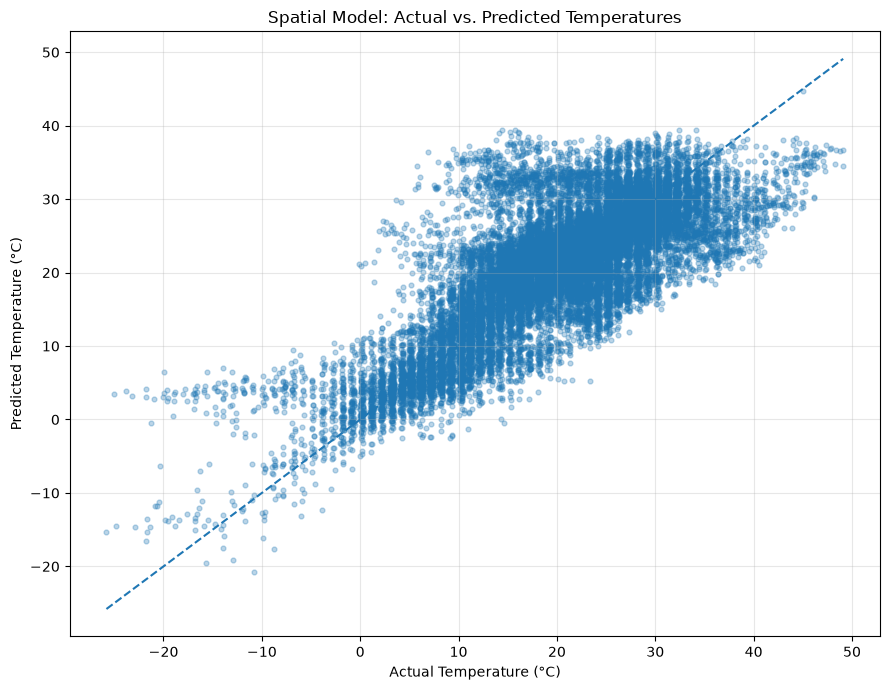

In [10]:
# Actual vs Predicted
plt.figure(figsize=(9, 7))

plt.scatter(
    y_test,
    spatial_predictions,
    alpha=0.3,
    s=12
)

min_value = min(y_test.min(), spatial_predictions.min())
max_value = max(y_test.max(), spatial_predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.title("Spatial Model: Actual vs. Predicted Temperatures")
plt.xlabel("Actual Temperature (°C)")
plt.ylabel("Predicted Temperature (°C)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

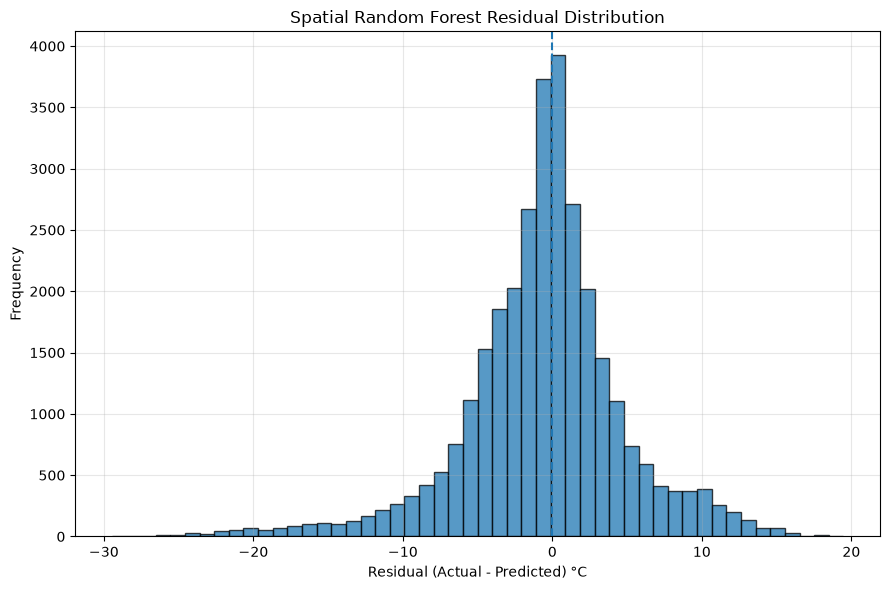

In [11]:
# Spatial Residual Distribution
plt.figure(figsize=(9, 6))

plt.hist(
    spatial_residuals,
    bins=50,
    edgecolor="black",
    alpha=0.75
)

plt.axvline(0, linestyle="--")

plt.title("Spatial Random Forest Residual Distribution")
plt.xlabel("Residual (Actual - Predicted) °C")
plt.ylabel("Frequency")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### Key Findings

The Spatial Random Forest prediction error analysis revealed the following:

- Mean residual: -0.6149°C.
- Residual standard deviation: 5.4207°C.
- Most residuals are concentrated around zero.
- The model tends to overestimate lower temperatures and underestimate higher temperatures.
- The prediction errors show considerable dispersion, particularly at extreme temperature ranges.

Compared with the chronological baseline, the spatial model exhibits greater prediction error variability.

These findings highlight the challenges of predicting temperatures at geographically unseen locations.

### 5.6 Comparing Baseline and Spatial Models

In this section, we will compare the chronological baseline model with the spatially validated model.

The comparison will highlight the impact of geographical separation on prediction performance.

#### 5.6.1 Performance Metrics Comparison

Compare the evaluation metrics of both models using a structured DataFrame.

In [12]:
# # Create Model Comparison DataFrame
# model_comparison = pd.DataFrame({
#     "Metric": ["MAE", "RMSE", "R2"],
#     "Chronological Baseline": [
#         3.0329,
#         4.1914,
#         0.6789
#     ],
#     "Spatial Validation": [
#         spatial_mae,
#         spatial_rmse,
#         spatial_r2
#     ]
# })

# display(model_comparison)


# ________________________



# Load Baseline Metrics
with open(RESULTS_DIR / "baseline_metrics.json", "r") as file:
    baseline_metrics = json.load(file)

# Create Model Comparison DataFrame
model_comparison = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2"],
    "Chronological Baseline": [
        baseline_metrics["MAE"],
        baseline_metrics["RMSE"],
        baseline_metrics["R2"]
    ],
    "Spatial Validation": [
        spatial_mae,
        spatial_rmse,
        spatial_r2
    ]
})

display(model_comparison.round(4))

,Metric,Chronological Baseline,Spatial Validation
0,MAE,3.0329,3.7928
1,RMSE,4.1914,5.4555
2,R2,0.6789,0.6043


#### Key Findings

The comparison between chronological and spatial validation revealed a noticeable performance difference.

- Chronological Baseline MAE: 3.0329°C.
- Spatial Validation MAE: 3.7928°C.
- Chronological Baseline RMSE: 4.1914°C.
- Spatial Validation RMSE: 5.4555°C.
- Chronological Baseline R²: 0.6789.
- Spatial Validation R²: 0.6043.

Compared with chronological validation, spatial validation resulted in:

- A 25.1% increase in MAE.
- A 30.2% increase in RMSE.
- A decrease of 0.0746 in R².

These results indicate weaker predictive performance on geographically unseen locations.

However, the two experiments use different test populations, so the observed performance difference should not be attributed exclusively to geographical separation.

#### 5.6.2 Visual Comparison of Model Performance

Visualize the performance differences between chronological and spatial validation using separate bar charts for MAE, RMSE, and R².

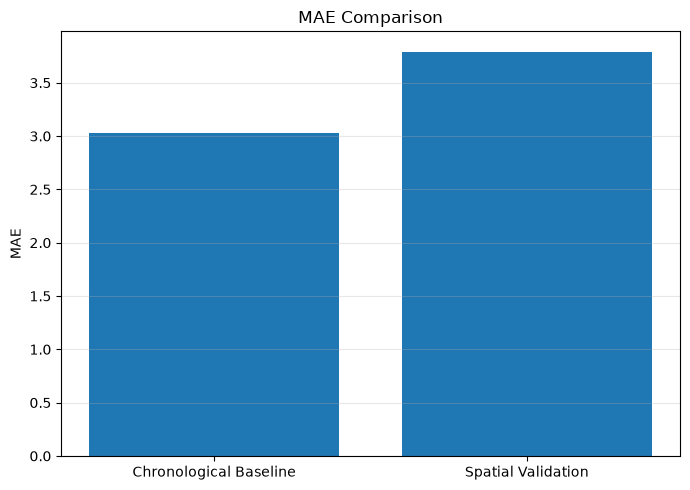

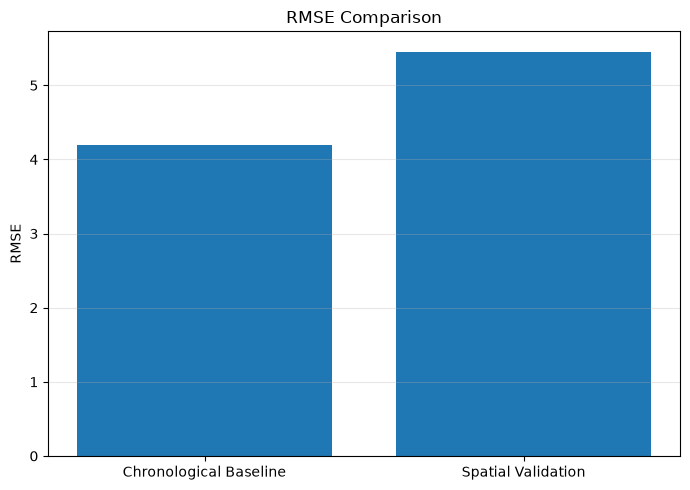

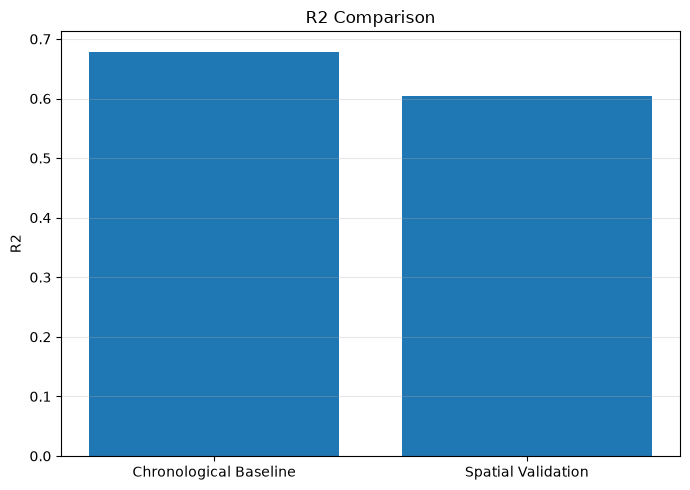

In [13]:
# Plot Model Performance Comparison
metrics = ["MAE", "RMSE", "R2"]

baseline_values = [
    baseline_metrics["MAE"],
    baseline_metrics["RMSE"],
    baseline_metrics["R2"]
]

spatial_values = [
    spatial_mae,
    spatial_rmse,
    spatial_r2
]

for metric, baseline_value, spatial_value in zip(
    metrics, baseline_values, spatial_values
):
    plt.figure(figsize=(7, 5))

    plt.bar(
        ["Chronological Baseline", "Spatial Validation"],
        [baseline_value, spatial_value]
    )

    plt.title(f"{metric} Comparison")
    plt.ylabel(metric)
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

#### Key Findings

The visual comparison highlights the performance differences between chronological and spatial validation.

- The chronological baseline achieved lower MAE and RMSE.
- The spatial model showed higher prediction errors.
- The chronological baseline achieved a higher R² score.
- The performance gap highlights the difficulty of generalizing to geographically unseen locations.

The visual results are consistent with the numerical evaluation metrics and support the findings of the spatial validation experiment.

### 5.7 Saving the Spatial Model and Results

In this section, we will save the trained spatial model and its evaluation metrics to support reproducibility and future model comparisons.

#### 5.7.1 Saving the Trained Spatial Model

Serialize the trained Spatial Random Forest model using Joblib with compression.

In [14]:
# Ensure Model Directory Exists
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# Define Model Path
SPATIAL_MODEL_PATH = MODELS_DIR / "random_forest_spatial.joblib"

# Save Spatial Model
joblib.dump(
    spatial_rf_model,
    SPATIAL_MODEL_PATH,
    compress=3
)

# Verify Saved Model
spatial_model_size = (
    SPATIAL_MODEL_PATH.stat().st_size / (1024**2)
)

print("Spatial model saved successfully.")
print("Model path:", SPATIAL_MODEL_PATH)
print(f"Model size: {spatial_model_size:.2f} MB")

Spatial model saved successfully.
Model path: D:\Users\PC\Desktop\To the new pc\Elzero\ML-Projects\Climate_Geospatial_ML\models\random_forest_spatial.joblib
Model size: 131.46 MB


#### 5.7.2 Verifying the Saved Spatial Model

Reload the saved spatial model and verify that it produces predictions consistent with the original trained model.

In [15]:
# Load Saved Spatial Model
loaded_spatial_model = joblib.load(SPATIAL_MODEL_PATH)

# Generate Predictions
loaded_spatial_predictions = loaded_spatial_model.predict(X_test)

# Verify Prediction Consistency
spatial_predictions_match = np.allclose(
    spatial_predictions,
    loaded_spatial_predictions
)

print("Spatial model loaded successfully.")
print("Prediction consistency:", spatial_predictions_match)

print(
    "Maximum prediction difference:",
    np.max(np.abs(spatial_predictions - loaded_spatial_predictions))
)

Spatial model loaded successfully.
Prediction consistency: True
Maximum prediction difference: 1.4210854715202004e-14


#### Key Findings

The saved Spatial Random Forest model was successfully reloaded and verified.

- The model was saved using Joblib with compression.
- The saved model was loaded successfully.
- Prediction consistency: True.
- Maximum prediction difference: approximately 1.42 × 10⁻¹⁴.

The verification confirms that the saved model produces numerically equivalent predictions to the original trained model.

#### 5.7.3 Saving Spatial Evaluation Metrics

Save the spatial model's evaluation metrics in JSON format to support reproducibility and direct comparison with the chronological baseline experiment.

In [16]:
# Ensure Results Directory Exists
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Collect Spatial Evaluation Metrics
spatial_metrics = {
    "model": "RandomForestRegressor",
    "validation_strategy": "Spatial GroupShuffleSplit",
    "training_observations": int(len(X_train)),
    "testing_observations": int(len(X_test)),
    "training_groups": int(len(train_groups)),
    "testing_groups": int(len(test_groups)),
    "MAE": float(spatial_mae),
    "RMSE": float(spatial_rmse),
    "R2": float(spatial_r2),
    "Mean_Residual": float(spatial_mean_residual),
    "Residual_Std": float(spatial_residual_std)
}

# Save Spatial Metrics
SPATIAL_METRICS_PATH = RESULTS_DIR / "spatial_metrics.json"

with open(SPATIAL_METRICS_PATH, "w") as file:
    json.dump(spatial_metrics, file, indent=4)

print("Spatial evaluation metrics saved successfully.")
print("Metrics path:", SPATIAL_METRICS_PATH)

display(spatial_metrics)

Spatial evaluation metrics saved successfully.
Metrics path: D:\Users\PC\Desktop\To the new pc\Elzero\ML-Projects\Climate_Geospatial_ML\outputs\results\spatial_metrics.json


{'model': 'RandomForestRegressor',
 'validation_strategy': 'Spatial GroupShuffleSplit',
 'training_observations': 139590,
 'testing_observations': 31337,
 'training_groups': 228,
 'testing_groups': 58,
 'MAE': 3.7927723440123184,
 'RMSE': 5.455478686188152,
 'R2': 0.6043299246363734,
 'Mean_Residual': -0.6148969708417015,
 'Residual_Std': 5.420714843145959}

#### Key Findings

The spatial model and its evaluation metrics were successfully saved.

- The trained model was saved in compressed Joblib format.
- Model size: 131.46 MB.
- The saved model was successfully reloaded and verified.
- Spatial evaluation metrics were saved in JSON format.
- Training observations: 139,590.
- Testing observations: 31,337.
- Training geographical groups: 228.
- Testing geographical groups: 58.

The saved artifacts provide a reproducible record of the spatial validation experiment and enable future comparisons with other models.